# Projet final : Aura Detector

*Classification de textes en français selon leur « aura » — Mastère Dev, Data & IA*

Plan de l'analyse :
- Import des librairies et paramètres
- Chargement et exploration des données
- D'où viennent nos étiquettes (la formule de l'aura)
- Préparation des données et choix de la métrique
- Modèle 1 : SVM
- Modèle 2 : CNN
- Modèle 3 : CamemBERT
- Comparaison des trois modèles sur le test
- Test sur des phrases choisies
- Ce qui se passe quand on envoie un texte dans la WebApp
- Conclusion

Notre idée : donner un texte à un modèle et qu'il nous dise quelle « aura » il dégage. On a défini 4 classes :

| Classe | Score | Exemple |
|---|---|---|
| Anti-Aura | −100 à −11 | « dab dab, six-seven » |
| Aura Correcte | −10 à +24 | « Le train a eu une heure de retard ce matin. » |
| Forte Aura | +25 à +74 | « Vous avez la mémoire courte et le discours long ! » |
| Aura Divine | +75 à +100 | « L'aura, c'est comme le wifi du voisin : ceux qui en parlent le plus sont ceux qui ne l'ont pas. » |

On note la façon de dire les choses, pas l'opinion : une pique bien tournée a de l'aura, une insulte n'en a pas.

On compare trois modèles, du plus simple au plus puissant : un SVM, un CNN et CamemBERT.

## Importation des librairies nécessaires

In [1]:
import os
import re
import json
import time
import random
import itertools
import collections
import subprocess
import sys
sys.path.insert(0, "scripts")   # nos scripts (téléchargement des modèles depuis Hugging Face)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

# scikit-learn : SVM, TF-IDF, recherche d'hyperparamètres et métriques
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report,
    make_scorer
)
import joblib

# PyTorch : pour le CNN (et CamemBERT, via la librairie transformers)
import torch
import torch.nn as nn

import warnings
warnings.filterwarnings("ignore") # ne pas afficher tous les Warnings

sns.set_theme(style="whitegrid") # pour les graphiques

**Commentaire :** 
On a pris PyTorch plutôt que Keras (utilisé dans le TP 2) parce que CamemBERT tourne sur PyTorch : comme ça, une seule librairie de deep learning pour le CNN et pour CamemBERT.

## Paramètres du projet

Tous les réglages sont dans cette cellule. Pour tester une idée, on change une ligne ici et on relance tout.

In [2]:
# ===================== DONNÉES =====================
TRAIN_FICHIERS = [
    "data/train_synthetique.csv",     # 6 991 textes générés (brainrot, SMS, poésie, politique…)
    "data/grok_textes.csv",           # 105 textes écrits par une autre IA (Grok)
    "data/paires_contrastees.csv",    # 902 textes : même sujet, aura opposée
    "data/train_registres.csv",       # 1 206 textes dans le style du test (Assemblée, théâtre, maximes…)
    "data/train_battle.csv",          # 371 textes de battle rap
    "data/train_joutes_reelles.csv",  # 97 vraies répliques du domaine public (Cyrano, Molière…)
]
VALIDATION = "data/val_domaine.csv"   # sert à choisir les hyperparamètres
TEST = "data/test_reel.csv"           # 330 vrais textes, regardés UNE seule fois à la fin

GRAINE = 42

CLASSES = ["Anti-Aura", "Aura Correcte", "Forte Aura", "Aura Divine"]
COURT = ["Anti", "Corr", "Fort", "Divi"]
COULEURS = ["#d9534f", "#5bc0de", "#f0ad4e", "#9b59b6"]

# ===================== 1) SVM : grille testée en entier =====================
SVM_GRILLE = {
    "C": [0.1, 0.3, 1, 3],                         # inverse de la régularisation
    "ngram_mots": [(1, 1), (1, 2)],                # mots seuls, ou mots + paires de mots
    "ngram_caracteres": [(2, 4), (2, 5), (3, 6)],  # morceaux de 2 à 6 lettres
    "class_weight": [None, "balanced"],            # « balanced » = plus de poids aux classes rares
}

# ===================== 2) CNN : recherche aléatoire =====================
CNN_ESPACE = {
    "embedding": [64, 128, 200],                                  # taille des vecteurs de mots
    "n_filtres": [50, 100, 200],                                  # nombre de filtres par largeur
    "largeurs": [[2, 3, 4], [1, 2, 3], [2, 3, 4, 5], [3, 4, 5]],  # largeur des filtres, en mots
    "dropout": [0.3, 0.5],
    "lr": [5e-4, 1e-3, 2e-3],                                     # taux d'apprentissage d'Adam
    "batch": [32, 64],
}
CNN_N_ESSAIS = 20   # nombre de combinaisons tirées au hasard
CNN_FIXE = dict(longueur_max=100, epochs_max=15, patience=3, min_freq=2)

# ===================== 3) CamemBERT =====================
ENTRAINER_CAMEMBERT = False   # True = relance un entraînement (≈ 8 min sur GPU, plusieurs heures sur CPU)
CAMEMBERT_MODELE = "almanach/camembert-base"
CAMEMBERT_MODE = "regression"  # "regression" ou "classification"
CAMEMBERT_LR = 3e-5

# True = écrase les modèles utilisés par la WebApp (models/svm.joblib et models/cnn/)
SAUVEGARDER_MODELES = False

# ===================== DÉMO =====================
PHRASES_DEMO = [
    "Je me suis chié dessus",
    "La bière c'est comme ma femme, brune et amer",
    "fort en chocolat",
    "dab dab, six-seven",
    "un accident de train a eu lieu en espagne ce samedi,",
    "En imposer pour ne pas avoir à imposer, voilà en quoi consiste le charisme.",
    "Loin des yeux, loin du cœur",
]

# Reproductibilité : on fixe toutes les graines aléatoires
random.seed(GRAINE)
np.random.seed(GRAINE)
torch.manual_seed(GRAINE)

# On utilise le GPU s'il y en a un (cuda sur PC, mps sur Mac), sinon le CPU
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
print("Calcul sur :", DEVICE)

Calcul sur : mps


**Commentaire :** 
`SAUVEGARDER_MODELES = False` évite d'écraser les modèles de la WebApp quand on relance le notebook juste pour le lire.

## Chargement du jeu de données

Il n'existe pas de jeu de données « aura » tout prêt, on l'a construit nous-mêmes. On a trois jeux :
- le **train**, pour apprendre ;
- la **validation**, pour choisir les hyperparamètres ;
- le **test** : 330 vrais textes (Assemblée nationale, théâtre, poésie…), qu'on ne regarde qu'une fois, à la fin.

In [3]:
def charger(fichiers):
    tables = [
        pd.read_csv(f, encoding="utf-8-sig")
        for f in fichiers
    ]
    df = pd.concat(tables, ignore_index=True)

    # on garde seulement les lignes avec un texte et une classe valide
    df = df[df["classe"].isin(CLASSES)].dropna(subset=["texte"])

    # y = numéro de la classe (0 = Anti, 1 = Correcte, 2 = Forte, 3 = Divine)
    df["y"] = df["classe"].map(CLASSES.index)

    return df.reset_index(drop=True)


train = charger(TRAIN_FICHIERS)
val = charger([VALIDATION])
test = charger([TEST])

# Sécurité anti-fuite : on retire du train tout texte présent dans la validation ou le test
textes_interdits = set(test["texte"]) | set(val["texte"])
n_avant = len(train)
train = train[~train["texte"].isin(textes_interdits)].reset_index(drop=True)

print("Textes retirés du train (déjà dans val/test) :", n_avant - len(train))
print("Train      :", train.shape)
print("Validation :", val.shape)
print("Test       :", test.shape)

Textes retirés du train (déjà dans val/test) : 1
Train      : (9671, 18)
Validation : (240, 13)
Test       : (330, 9)


**Commentaire :** 
On a 9 671 textes pour apprendre. On a retiré du train un texte qui était aussi dans le test : sinon le modèle aurait vu la réponse pendant l'entraînement.

## Exploration des données

Comme dans le TP Banking77, on commence par les dimensions et les premières lignes.

In [4]:
print("Nombre d'observations (train) :", train.shape[0])
print("Nombre de variables (train)   :", train.shape[1])
print("Nombre de classes             :", train["classe"].nunique())

display(train[["texte", "classe", "score"]].head())

Nombre d'observations (train) : 9671
Nombre de variables (train)   : 18
Nombre de classes             : 4


,texte,classe,score
0,Je laisse derrière moi des portes entrouvertes...,Forte Aura,64
1,Je cuisine mieux que je ne promets. Écris-moi ...,Forte Aura,46
2,Je laisse derrière moi des portes entrouvertes...,Forte Aura,60
3,"Ta présentation tout à l'heure, j'en rêve enco...",Aura Correcte,14
4,« Ode au silence »\n\nJe n'ai jamais prié qu'u...,Aura Divine,83


**Commentaire :** 
Chaque texte a une classe et un score d'aura entre −100 et +100. La classe, c'est juste le score rangé dans une des 4 cases.

In [5]:
print("Valeurs manquantes par colonne (texte / classe / score) :")
print(train[["texte", "classe", "score"]].isna().sum())

print("\nDoublons de texte dans le train :", train["texte"].duplicated().sum())

print("\nRépartition des classes dans le train :")
print(train["classe"].value_counts())

Valeurs manquantes par colonne (texte / classe / score) :
texte     0
classe    0
score     0
dtype: int64

Doublons de texte dans le train : 5

Répartition des classes dans le train :
classe
Aura Correcte    2724
Forte Aura       2712
Anti-Aura        2664
Aura Divine      1571
Name: count, dtype: int64


**Commentaire :** 
Pas de valeurs manquantes, et seulement 5 doublons, qu'on garde. Le train est assez équilibré, sauf Divine qui est un peu moins représentée (1 571 textes contre environ 2 700 pour les autres).

On compare la répartition des classes dans les trois jeux.

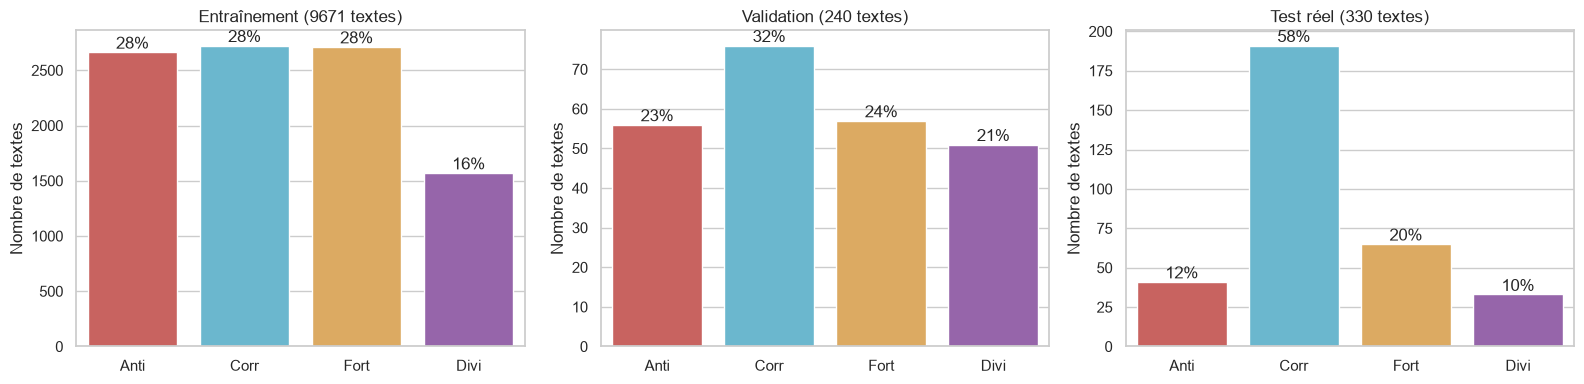

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (nom, df) in zip(axes, [("Entraînement", train), ("Validation", val), ("Test réel", test)]):

    effectifs = df["classe"].value_counts().reindex(CLASSES)

    sns.barplot(
        x=COURT,
        y=effectifs.values,
        palette=COULEURS,
        ax=ax
    )

    # on écrit le pourcentage au-dessus de chaque barre
    for i, v in enumerate(effectifs.values):
        ax.text(i, v, f"{v / effectifs.sum():.0%}", ha="center", va="bottom")

    ax.set_title(f"{nom} ({len(df)} textes)")
    ax.set_ylabel("Nombre de textes")

plt.tight_layout()
plt.show()

**Commentaire :** 
Le test est très déséquilibré : 58 % des textes sont « Correcte ». C'est normal, dans la vraie vie la plupart des phrases sont banales. Mais du coup, un modèle qui répondrait toujours « Correcte » aurait 58 % d'accuracy sans rien comprendre. On ne pourra donc pas juger nos modèles sur l'accuracy.

Longueur des textes, en nombre de mots :

,train : mots,test : mots
count,9671.0,330.0
mean,23.5,11.4
std,15.5,6.3
min,1.0,1.0
25%,13.0,7.0
50%,20.0,10.0
75%,29.0,15.0
max,107.0,40.0


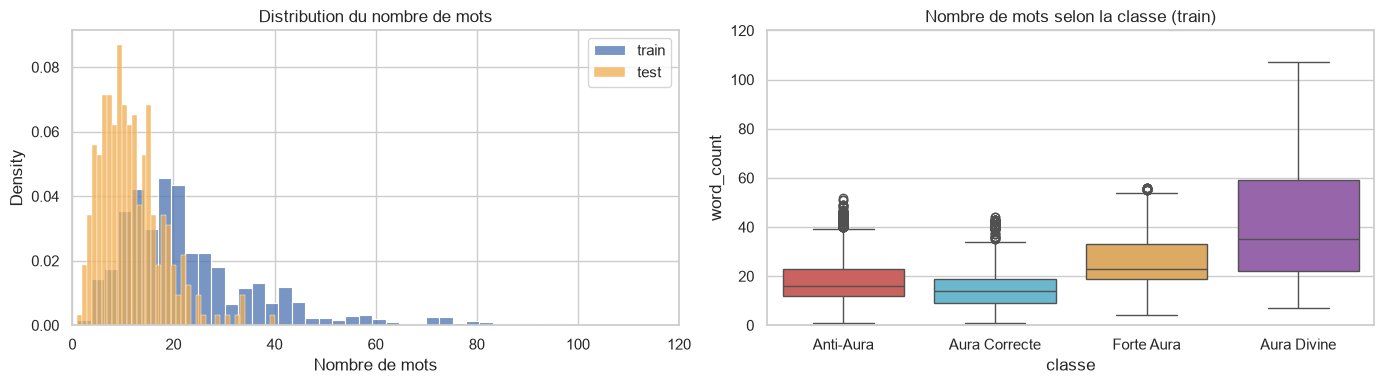

In [7]:
for df in [train, test]:
    df["text_length"] = df["texte"].apply(len)                 # nombre de caractères (espaces compris)
    df["word_count"] = df["texte"].apply(lambda x: len(x.split()))  # split() isole les mots

display(pd.DataFrame({
    "train : mots": train["word_count"].describe(),
    "test : mots": test["word_count"].describe(),
}).round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(train["word_count"], bins=40, stat="density", label="train", ax=axes[0])
sns.histplot(test["word_count"], bins=40, stat="density", label="test", color="#f0ad4e", ax=axes[0])
axes[0].set_title("Distribution du nombre de mots")
axes[0].set_xlabel("Nombre de mots")
axes[0].set_xlim(0, 120)
axes[0].legend()

sns.boxplot(data=train, x="classe", y="word_count", order=CLASSES, palette=COULEURS, ax=axes[1])
axes[1].set_title("Nombre de mots selon la classe (train)")
axes[1].set_ylim(0, 120)

plt.tight_layout()
plt.show()

**Commentaire :** 
Les textes du test sont très courts : 11 mots en moyenne, contre 23 dans le train. Avec si peu de mots, il y a peu d'indices pour le modèle.

Le graphique de droite montre un piège : dans le train, les textes Divine sont deux fois plus longs que les autres (ce sont souvent des petits poèmes générés). Un modèle pourrait apprendre « long = Divine », ce qui ne marchera pas sur le test.

Quelques exemples de vrais textes du test, pour chaque classe :

In [8]:
for classe in CLASSES:
    print(f"===== {classe} =====")
    exemples = test[test["classe"] == classe].sample(3, random_state=GRAINE)
    for _, ligne in exemples.iterrows():
        print(f"  [{ligne['score']:+.0f}] ({ligne['type']}) {ligne['texte'][:110]}")
    print()

===== Anti-Aura =====
  [-40] (théâtre) Au secours ! À la garde !
  [-45] (fable) La chétive pécore
S'enfla si bien qu'elle creva.
  [-13] (interjection) Mais ça va pas ?

===== Aura Correcte =====
  [+22] (discours) Nous, ici, avec Marine Le Pen, nous sommes le cri du peuple.
  [-4] (procédure) La conférence des présidents a décidé ce matin que la discussion des deux motions de censure aurait lieu ce je
  [-8] (interjection) C’est vous !

===== Forte Aura =====
  [+55] (débat) Vous voulez moins de riches, je veux moins de pauvres.
  [+42] (conférence de presse) Je veux que les joueurs dorment aussi bien que moi, c'est-à-dire pas du tout. C'est ce que je leur souhaite.
  [+32] (discours) Soit on change, soit on sera changé. Le dégagisme, c’est cela.

===== Aura Divine =====
  [+85] (prose) la tragédie de la mort est en ceci qu’elle transforme la vie en destin
  [+88] (théâtre) Mais on ne se bat pas dans l'espoir du succès !
Non ! non, c'est bien plus beau lorsque c'est inutile !
  [+80

**Commentaire :** 
Ça montre que la tâche est difficile : les textes sont courts et c'est souvent un détail de tournure qui change la classe. La frontière entre Forte et Divine est assez subjective.

Les mots les plus fréquents du train :

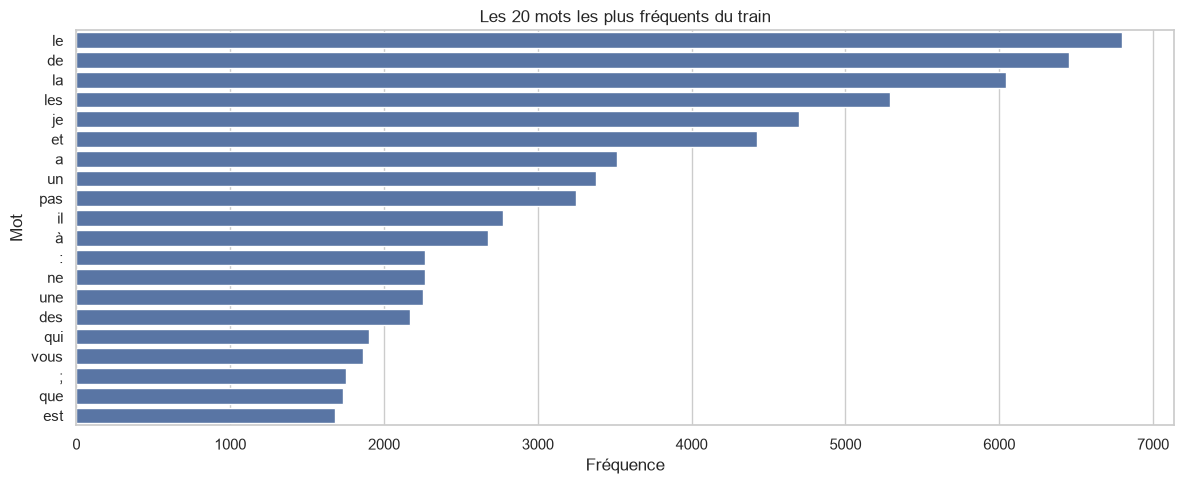

In [9]:
all_words = " ".join(train["texte"].astype(str)).lower().split()

word_counts = Counter(all_words)

most_common_words = word_counts.most_common(20)

words_df = pd.DataFrame(
    most_common_words,
    columns=["Mot", "Fréquence"]
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=words_df,
    x="Fréquence",
    y="Mot"
)

plt.title("Les 20 mots les plus fréquents du train")
plt.tight_layout()
plt.show()

**Commentaire :** 
Ce sont des mots comme « de », « la », « je » : ils sont partout, donc ils n'aident pas à distinguer les classes. C'est pour ça qu'on utilisera le TF-IDF pour le SVM, qui diminue le poids de ces mots.

Est-ce que notre train ressemble au test ?

In [10]:
def profil(df):
    t = df["texte"]
    return {
        "mots par texte": t.str.split().str.len().mean(),
        "% avec « ! »": t.str.contains("!").mean() * 100,
        "% avec emoji": t.str.contains(r"[\U0001F300-\U0001FAFF]").mean() * 100,
    }

display(pd.DataFrame({
    "train synthétique": profil(charger(["data/train_synthetique.csv"])),
    "train complet": profil(train),
    "test réel": profil(test),
}).round(1))

print("Types de textes du test :")
print(test["type"].value_counts().head(8))

,train synthétique,train complet,test réel
mots par texte,26.4,23.5,11.4
% avec « ! »,4.9,4.8,31.5
% avec emoji,11.1,8.3,0.0


Types de textes du test :
type
discours        101
interjection     65
théâtre          35
poésie           22
question         20
réponse          18
roman            11
prose            10
Name: count, dtype: int64


**Commentaire :** 
Non, et c'est le problème principal du projet. Nos premiers textes générés avaient des emojis et des phrases longues. Le test, ce sont de vrais textes courts, sans emoji, avec beaucoup de « ! ».

Pour réduire l'écart, on a écrit des textes en plus dans le style du test (Assemblée, battles, répliques de théâtre). Le train complet se rapproche un peu du test, mais l'écart reste grand.

## D'où viennent nos étiquettes : la formule de l'aura

Chaque texte de notre jeu a reçu 5 notes entre −100 et +100 :

| Lettre | Critère | Poids |
|---|---|---|
| R | Rizz : la phrase fait-elle mouche ? | 6 |
| S | Statut : celui qui parle se met-il en position de force ? | 4 |
| O | Originalité | 3 |
| B | Beauté du style | 3 |
| P | Poésie : rythme, rimes | 2 |

On en fait une moyenne pondérée :

$$
\text{Score} = \frac{6R + 4S + 3O + 3B + 2P}{18}
$$

Puis on range le score dans une classe : Anti-Aura jusqu'à −11, Correcte de −10 à 24, Forte de 25 à 74, Divine à partir de 75.

On a mis le plus de poids sur R et S, parce que pour nous l'aura c'est surtout l'impact et l'assurance. Des rimes seules ne suffisent pas.

In [11]:
POIDS = {"R": 6/18, "S": 4/18, "O": 3/18, "B": 3/18, "P": 2/18}
SEUILS = [-10.5, 24.5, 74.5]   # frontières entre Anti | Correcte | Forte | Divine


def score_aura(R, S, O, B, P):
    return POIDS["R"]*R + POIDS["S"]*S + POIDS["O"]*O + POIDS["B"]*B + POIDS["P"]*P


def classe_aura(score):
    return CLASSES[int(np.digitize(score, SEUILS))]


# Exemple : même situation, deux façons de réagir (une paire de train_registres)
exemples = {
    "« C'est honteux ! Honteux ! »": dict(R=-30, S=-15, O=-40, B=-25, P=-20),
    "« Honteux ? Non : prévisible, ce qui est pire. »": dict(R=40, S=40, O=45, B=40, P=35),
}

for texte, notes in exemples.items():
    s = score_aura(**notes)
    detail = " + ".join(f"{POIDS[k]:.3f}×{v}" for k, v in notes.items())
    print(f"{texte}\n   score = {detail} = {s:.1f}  →  {classe_aura(s)}\n")

« C'est honteux ! Honteux ! »
   score = 0.333×-30 + 0.222×-15 + 0.167×-40 + 0.167×-25 + 0.111×-20 = -26.4  →  Anti-Aura

« Honteux ? Non : prévisible, ce qui est pire. »
   score = 0.333×40 + 0.222×40 + 0.167×45 + 0.167×40 + 0.111×35 = 40.3  →  Forte Aura



**Commentaire :** 
Les deux textes parlent de la même chose. Le premier crie sans rien dire de neuf, toutes ses notes sont négatives. Le second répond par une pique calme, il passe en Forte Aura. C'est ce genre de différence que les modèles doivent apprendre, alors que les mots sont presque les mêmes.

1577 textes du train ont le détail des 5 notes R, S, O, B, P.
Écart max entre la formule et le score annoté : 0.50
Classe retrouvée par les seuils : 100%


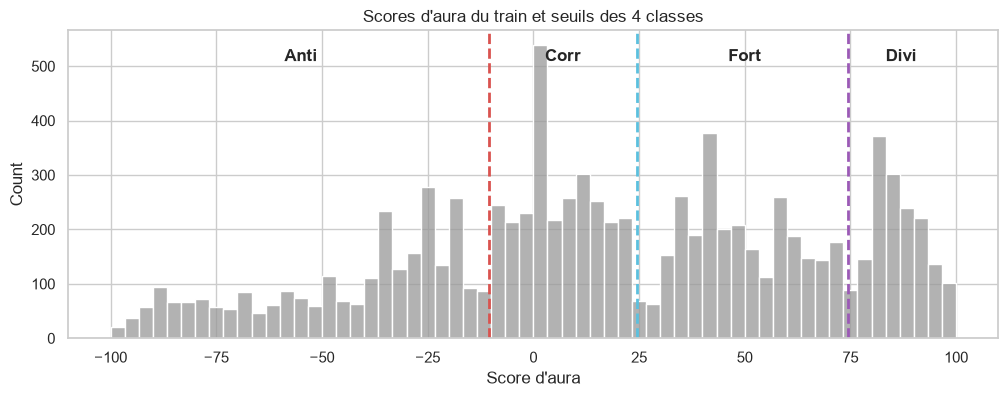

In [12]:
lettres = list(POIDS)
avec_notes = train.dropna(subset=lettres)

# la formule redonne-t-elle bien le score et la classe annotés ?
recalcul = score_aura(*(avec_notes[k] for k in lettres))
print(f"{len(avec_notes)} textes du train ont le détail des 5 notes R, S, O, B, P.")
print(f"Écart max entre la formule et le score annoté : {(recalcul - avec_notes['score']).abs().max():.2f}")
print(f"Classe retrouvée par les seuils : {(recalcul.map(classe_aura) == avec_notes['classe']).mean():.0%}")

plt.figure(figsize=(12, 4))
sns.histplot(train["score"], bins=60, color="#999")
for s, c in zip(SEUILS, ["#d9534f", "#5bc0de", "#9b59b6"]):
    plt.axvline(s, color=c, ls="--", lw=2)
for x, nom in zip([-55, 7, 50, 87], COURT):
    plt.text(x, plt.ylim()[1] * 0.9, nom, ha="center", fontweight="bold")
plt.title("Scores d'aura du train et seuils des 4 classes")
plt.xlabel("Score d'aura")
plt.show()

**Commentaire :** 
La formule redonne bien la classe de 100 % des textes qui ont les 5 notes : nos étiquettes sont cohérentes.

Deux choses à retenir : les modèles ne voient jamais les 5 notes, seulement le texte. Et les classes ont un ordre (Anti < Correcte < Forte < Divine), donc confondre Anti et Divine est bien plus grave que confondre Forte et Divine.

## Préparation des données

On sépare le texte (X) de la classe (y).

Dans le TP Banking77, on faisait une validation croisée sur le train. Ici ça ne marcherait pas : notre train est en grande partie généré et ne ressemble pas au test. On utilise plutôt une validation écrite dans le style du test, et `PredefinedSplit` pour dire à `GridSearchCV` « entraîne sur le train, note sur la validation ».

In [13]:
X_train, y_train = train["texte"].astype(str), train["y"].values
X_val, y_val = val["texte"].astype(str), val["y"].values
X_test, y_test = test["texte"].astype(str), test["y"].values

# train + validation mis bout à bout ; -1 = « toujours dans le train », 0 = « pli de validation »
X_train_val = pd.concat([X_train, X_val])
y_train_val = np.concatenate([y_train, y_val])

decoupe = PredefinedSplit(
    [-1] * len(X_train) + [0] * len(X_val)
)

print("Train      :", X_train.shape)
print("Validation :", X_val.shape)
print("Test       :", X_test.shape)

Train      : (9671,)
Validation : (240,)
Test       : (330,)


**Commentaire :** 
Le test n'est utilisé nulle part avant la comparaison finale. Le TF-IDF et le vocabulaire du CNN seront appris sur le train uniquement.

## Comment mesurer les performances

L'accuracy ne marche pas ici (58 % en répondant toujours « Correcte »). On utilise le **kappa quadratique**. L'idée :

$$
\kappa = \frac{\text{accord observé} - \text{accord dû au hasard}}{1 - \text{accord dû au hasard}}
$$

- 1 = modèle parfait ;
- 0 = pas mieux que le hasard ;
- « quadratique » : une erreur coûte le carré de l'écart. Se tromper de 3 classes coûte 9 fois plus que se tromper d'une seule. Ça colle à nos classes ordonnées.

On regarde aussi le F1-macro, qui donne autant d'importance à la petite classe Divine qu'aux autres.

In [14]:
def kappa(y_vrai, y_pred):
    return cohen_kappa_score(y_vrai, y_pred, weights="quadratic")


RESULTATS = {}     # métriques de chaque modèle sur le test
PREDICTIONS = {}   # prédictions de chaque modèle sur le test


def evaluer(nom, y_pred, temps_entrainement=None, n_parametres=None):
    y_pred = np.asarray(y_pred)
    PREDICTIONS[nom] = y_pred
    rappel = recall_score(y_test, y_pred, labels=range(4), average=None, zero_division=0)
    RESULTATS[nom] = {
        "kappa": kappa(y_test, y_pred),
        "F1-macro": f1_score(y_test, y_pred, average="macro"),
        "accuracy": accuracy_score(y_test, y_pred),
        "à ±1 classe": np.mean(abs(y_test - y_pred) <= 1),
        **{f"rappel {c}": r for c, r in zip(COURT, rappel)},
        "entraînement (s)": temps_entrainement,
        "paramètres": n_parametres,
    }
    print(f"{nom} → kappa test {RESULTATS[nom]['kappa']:.3f} | F1-macro {RESULTATS[nom]['F1-macro']:.3f} | accuracy {RESULTATS[nom]['accuracy']:.0%}")


# Deux références « bêtes » pour savoir à partir de quand un modèle sert à quelque chose
evaluer("Toujours « Aura Correcte »", np.ones(len(y_test), dtype=int))
evaluer("Hasard", np.random.RandomState(GRAINE).randint(0, 4, len(y_test)))

Toujours « Aura Correcte » → kappa test 0.000 | F1-macro 0.183 | accuracy 58%
Hasard → kappa test -0.075 | F1-macro 0.202 | accuracy 23%


**Commentaire :** 
Répondre toujours « Correcte » donne 58 % d'accuracy mais un kappa de 0. Le hasard donne lui aussi un kappa proche de 0. Un modèle n'est utile que si son kappa est nettement au-dessus.

## Modèle 1 : SVM

**Comment ça marche.** On transforme d'abord chaque texte en nombres avec le TF-IDF. Pour chaque terme (un mot, une paire de mots ou un morceau de lettres) :

$$
\text{TF-IDF} = \text{fréquence du terme dans le texte} \times \log\frac{\text{nombre de textes}}{\text{nombre de textes qui contiennent ce terme}}
$$

Un terme fréquent dans le texte mais rare ailleurs pèse lourd. « de » ou « la », présents partout, pèsent presque rien.

On fait un TF-IDF sur les mots et un autre sur les morceaux de lettres (par exemple « chao », « aos »). Les morceaux de lettres aident beaucoup avec l'argot et les fautes.

Ensuite, le SVM cherche la frontière qui sépare le mieux les classes, en gardant le plus de marge possible.

**Les hyperparamètres testés :**

| Hyperparamètre | Rôle | Valeurs |
|---|---|---|
| C | Petit C = modèle prudent, grand C = colle au train (risque d'apprendre par cœur) | 0,1 ; 0,3 ; 1 ; 3 |
| n-grammes de mots | Mots seuls, ou aussi les paires de mots | (1,1) ; (1,2) |
| n-grammes de lettres | Taille des morceaux de lettres | (2,4) ; (2,5) ; (3,6) |
| class_weight | `balanced` donne plus de poids aux classes rares | None ; balanced |

**Pourquoi le SVM ?** C'est la référence classique pour le texte (c'était le meilleur modèle du TP 2). Il est rapide et simple : si un modèle plus compliqué ne fait pas mieux, il ne sert à rien.

In [15]:
svm = Pipeline([
    ("tfidf", FeatureUnion([
        ("mots", TfidfVectorizer(
            analyzer="word",
            min_df=2,            # on ignore les termes vus dans un seul texte
            sublinear_tf=True    # 1 + log(tf)
        )),
        ("caracteres", TfidfVectorizer(
            analyzer="char_wb",  # morceaux de lettres à l'intérieur des mots
            min_df=2,
            sublinear_tf=True
        )),
    ])),
    ("svm", LinearSVC(
        max_iter=5000
    ))
])

**Commentaire :** 
Comme dans le TP, TF-IDF et SVM sont dans un même `Pipeline` : le TF-IDF est réappris à chaque essai, sans jamais voir la validation.

Le SVM est rapide, on teste donc toutes les combinaisons : 4 × 2 × 3 × 2 = 48.

In [16]:
param_grid = {
    "svm__C": SVM_GRILLE["C"],
    "tfidf__mots__ngram_range": SVM_GRILLE["ngram_mots"],
    "tfidf__caracteres__ngram_range": SVM_GRILLE["ngram_caracteres"],
    "svm__class_weight": SVM_GRILLE["class_weight"],
}

grid = GridSearchCV(
    estimator=svm,
    param_grid=param_grid,
    scoring=make_scorer(kappa),   # on optimise directement notre métrique
    cv=decoupe,                   # train → validation (PredefinedSplit)
    n_jobs=-1,
    refit=False
)

start = time.perf_counter()
grid.fit(X_train_val, y_train_val)
print(f"{len(grid.cv_results_['params'])} combinaisons testées en {time.perf_counter() - start:.0f} secondes")

tableau_svm = pd.DataFrame(grid.cv_results_["params"])
tableau_svm["kappa_validation"] = grid.cv_results_["mean_test_score"]
tableau_svm.columns = ["C", "class_weight", "ngram_caracteres", "ngram_mots", "kappa_validation"]

display(tableau_svm.sort_values("kappa_validation", ascending=False).head(10).round(3))

48 combinaisons testées en 20 secondes


,C,class_weight,ngram_caracteres,ngram_mots,kappa_validation
17,0.3,NaN,"(3, 6)","(1, 2)",0.743
30,1.0,balanced,"(2, 4)","(1, 1)",0.738
11,0.1,balanced,"(3, 6)","(1, 2)",0.733
24,1.0,NaN,"(2, 4)","(1, 1)",0.733
0,0.1,NaN,"(2, 4)","(1, 1)",0.733
23,0.3,balanced,"(3, 6)","(1, 2)",0.732
19,0.3,balanced,"(2, 4)","(1, 2)",0.730
6,0.1,balanced,"(2, 4)","(1, 1)",0.725
8,0.1,balanced,"(2, 5)","(1, 1)",0.725
1,0.1,NaN,"(2, 4)","(1, 2)",0.723


**Commentaire :** 
Meilleur réglage : C = 0,3, sans pondération, mots + paires de mots, morceaux de 3 à 6 lettres (kappa de validation 0,743). Mais les 10 meilleurs sont tous entre 0,72 et 0,74 : pour le SVM, le réglage change peu de chose.

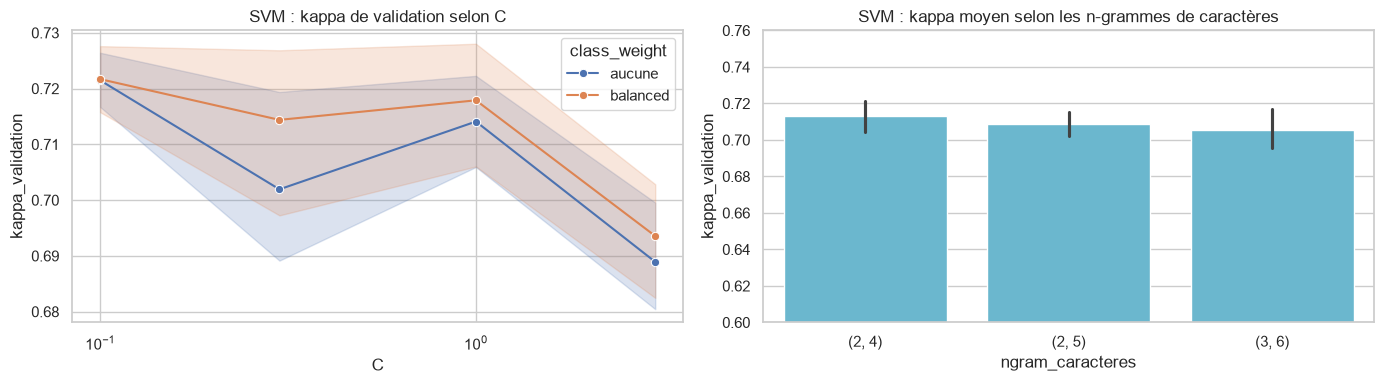

In [17]:
tableau_svm["class_weight"] = tableau_svm["class_weight"].fillna("aucune")
tableau_svm["ngram_caracteres"] = tableau_svm["ngram_caracteres"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.lineplot(data=tableau_svm, x="C", y="kappa_validation", hue="class_weight", marker="o", ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_title("SVM : kappa de validation selon C")

sns.barplot(data=tableau_svm, x="ngram_caracteres", y="kappa_validation", ax=axes[1], color="#5bc0de")
axes[1].set_ylim(0.6, 0.76)
axes[1].set_title("SVM : kappa moyen selon les n-grammes de caractères")

plt.tight_layout()
plt.show()

**Commentaire :** 
Le kappa est stable entre C = 0,1 et C = 1, puis chute à C = 3 : le modèle commence à apprendre le train par cœur. Les autres réglages changent très peu le résultat.

On réentraîne le SVM avec les meilleurs réglages et on l'évalue sur le test.

Le SVM ne donne pas de probabilité, juste un score. Pour la WebApp, on le « calibre » avec `CalibratedClassifierCV`, qui transforme ces scores en probabilités.

In [18]:
meilleurs = grid.best_params_
print("Meilleurs hyperparamètres :", meilleurs)
print("Kappa de validation       :", round(grid.best_score_, 3))

svm.set_params(**meilleurs)

start = time.perf_counter()
svm.fit(X_train, y_train)
t_svm = time.perf_counter() - start

y_pred_svm = svm.predict(X_test)
evaluer("1. SVM", y_pred_svm, t_svm, int(svm["svm"].coef_.size + svm["svm"].intercept_.size))

print()
print(classification_report(y_test, y_pred_svm, target_names=CLASSES, zero_division=0))

# Version calibrée (avec probabilités) pour la WebApp
svm_proba = Pipeline([
    ("tfidf", svm["tfidf"]),
    ("svm", CalibratedClassifierCV(
        LinearSVC(C=meilleurs["svm__C"], class_weight=meilleurs["svm__class_weight"], max_iter=5000),
        cv=3
    ))
])
svm_proba.fit(X_train, y_train)

if SAUVEGARDER_MODELES:
    os.makedirs("models", exist_ok=True)
    joblib.dump(svm_proba, "models/svm.joblib")
    print("SVM sauvegardé dans models/svm.joblib")

Meilleurs hyperparamètres : {'svm__C': 0.3, 'svm__class_weight': None, 'tfidf__caracteres__ngram_range': (3, 6), 'tfidf__mots__ngram_range': (1, 2)}
Kappa de validation       : 0.743


1. SVM → kappa test 0.147 | F1-macro 0.297 | accuracy 35%

               precision    recall  f1-score   support

    Anti-Aura       0.19      0.46      0.27        41
Aura Correcte       0.69      0.37      0.48       191
   Forte Aura       0.23      0.32      0.27        65
  Aura Divine       0.16      0.18      0.17        33

     accuracy                           0.35       330
    macro avg       0.32      0.33      0.30       330
 weighted avg       0.48      0.35      0.38       330



**Commentaire :** 
Grosse chute : 0,74 en validation, mais seulement 0,15 sur le test (35 % d'accuracy). Notre validation, écrite par nous, était trop facile. Sur de vrais textes, le SVM ne retrouve pas les mots qu'il a vus à l'entraînement.

Il ne retrouve que 37 % des textes « Correcte » : comme il a appris sur un train équilibré, il voit de l'aura un peu partout.

## Modèle 2 : CNN

**Comment ça marche.** C'est un réseau de neurones qu'on entraîne de zéro (architecture de Kim, 2014) :

texte → mots → vecteurs → filtres → max → 4 classes

1. Chaque mot devient un vecteur de nombres, appris par le réseau (l'*embedding*).
2. Des **filtres** glissent sur la phrase en regardant 1, 2 ou 3 mots à la fois. Chaque filtre apprend à repérer un motif, par exemple « c'est vous ! ».
3. Pour chaque filtre, on garde l'endroit de la phrase où le motif est le plus fort (*max-pooling*).
4. Une dernière couche donne une probabilité pour chacune des 4 classes.

Pendant l'entraînement, on éteint au hasard une partie des neurones (*dropout*) pour éviter que le réseau apprenne par cœur. On donne aussi plus de poids aux erreurs sur la classe Divine, plus rare. Et comme dans le TP 2, on arrête l'entraînement quand le kappa de validation ne progresse plus pendant 3 epochs (*early stopping*).

**Pourquoi un CNN et pas un LSTM ?** Nos textes sont courts et l'aura tient souvent dans quelques mots (une chute, une formule) : c'est exactement ce que repèrent les filtres. En plus, le CNN est beaucoup plus rapide qu'un LSTM, ce qui nous a permis de tester 20 configurations.

Le CNN prend une suite de numéros de mots, comme les séquences IMDB du TP 2. On découpe le texte en mots, on construit le vocabulaire **sur le train uniquement**, puis on remplace chaque mot par son numéro.

In [19]:
def tokeniser(texte):
    # minuscules ; sépare les élisions (« l'aura » -> « l' » + « aura ») ; garde la ponctuation et les emojis
    return re.findall(r"[^\W_]+['’](?=[^\W_])|[^\W_]+|[^\w\s]", str(texte).lower())


def construire_vocab(textes, min_freq=2):
    # 0 = remplissage (padding), 1 = mot inconnu ; on ignore les mots vus moins de min_freq fois
    compte = collections.Counter(m for t in textes for m in tokeniser(t))
    mots = sorted(m for m, c in compte.items() if c >= min_freq)
    return {m: i + 2 for i, m in enumerate(mots)}


def encoder(textes, vocab, longueur_max, longueur_min=5):
    ids = [[vocab.get(m, 1) for m in tokeniser(t)][:longueur_max] or [1] for t in textes]
    L = max(longueur_min, max(map(len, ids)))   # au moins la largeur du plus grand filtre
    X = torch.zeros(len(ids), L, dtype=torch.long)
    for i, s in enumerate(ids):
        X[i, :len(s)] = torch.tensor(s)
    return X


exemple = "Vous avez la mémoire courte et le discours long !"
vocab_exemple = construire_vocab(X_train, min_freq=2)
print("Tokens  :", tokeniser(exemple))
print("Numéros :", encoder([exemple], vocab_exemple, 100)[0].tolist())
print("Taille du vocabulaire (min_freq=2) :", len(vocab_exemple))

Tokens  : ['vous', 'avez', 'la', 'mémoire', 'courte', 'et', 'le', 'discours', 'long', '!']
Numéros : [4065, 480, 2071, 2438, 1049, 1483, 2099, 1211, 2162, 2]
Taille du vocabulaire (min_freq=2) : 4261


**Commentaire :** 
« l' » est séparé du mot qui suit, pour que « aura » soit reconnu quel que soit l'article. On garde la ponctuation : un texte plein de « ! » n'a pas la même énergie qu'une phrase posée. Les mots vus une seule fois deviennent « inconnu » (numéro 1).

### Le réseau

In [20]:
class TextCNN(nn.Module):

    def __init__(self, n_mots, embedding=128, n_filtres=100, largeurs=(2, 3, 4), dropout=0.5, n_classes=4):
        super().__init__()
        # 1) Embedding : numéro de mot -> vecteur de taille « embedding »
        self.emb = nn.Embedding(n_mots, embedding, padding_idx=0)
        # 2) Une convolution par largeur de filtre (ex : 1, 2 et 3 mots)
        self.convs = nn.ModuleList([
            nn.Conv1d(embedding, n_filtres, k)
            for k in largeurs
        ])
        # 4) Dropout
        self.drop = nn.Dropout(dropout)
        # 5) Couche de sortie : 4 classes
        self.sortie = nn.Linear(n_filtres * len(largeurs), n_classes)

    def forward(self, x):
        e = self.emb(x).transpose(1, 2)                  # (batch, embedding, mots)
        h = [
            torch.relu(conv(e)).max(dim=2).values        # 3) ReLU puis max-pooling sur toute la phrase
            for conv in self.convs
        ]
        return self.sortie(self.drop(torch.cat(h, dim=1)))


reseau = TextCNN(len(vocab_exemple) + 2)
print(reseau)
print("Nombre de paramètres :", sum(p.numel() for p in reseau.parameters()))

TextCNN(
  (emb): Embedding(4263, 128, padding_idx=0)
  (convs): ModuleList(
    (0): Conv1d(128, 100, kernel_size=(2,), stride=(1,))
    (1): Conv1d(128, 100, kernel_size=(3,), stride=(1,))
    (2): Conv1d(128, 100, kernel_size=(4,), stride=(1,))
  )
  (drop): Dropout(p=0.5, inplace=False)
  (sortie): Linear(in_features=300, out_features=4, bias=True)
)
Nombre de paramètres : 662368


**Commentaire :** 
La plupart des 662 000 paramètres sont dans l'embedding (un vecteur par mot du vocabulaire). C'est donc la taille de l'embedding qui décide de la taille du réseau.

### L'entraînement

In [21]:
@torch.no_grad()
def predire_proba(modele, X, device, lot=256):
    modele.eval()
    return torch.cat([
        modele(X[i:i + lot].to(device)).softmax(1).cpu()
        for i in range(0, len(X), lot)
    ]).numpy()


def entrainer_cnn(cfg, device, graine=GRAINE):
    torch.manual_seed(graine)
    np.random.seed(graine)

    # vocabulaire appris sur le TRAIN uniquement
    vocab = construire_vocab(X_train, cfg["min_freq"])
    Xtr = encoder(X_train, vocab, cfg["longueur_max"])
    Xva = encoder(X_val, vocab, cfg["longueur_max"])
    ytr = torch.tensor(y_train)

    # poids des classes c_k = n / (K * n_k)
    poids = torch.tensor(len(y_train) / (4 * np.bincount(y_train, minlength=4)), dtype=torch.float, device=device)

    modele = TextCNN(len(vocab) + 2, cfg["embedding"], cfg["n_filtres"], tuple(cfg["largeurs"]), cfg["dropout"]).to(device)
    optimiseur = torch.optim.Adam(modele.parameters(), lr=cfg["lr"])
    critere = nn.CrossEntropyLoss(weight=poids)

    hist = {"perte_train": [], "kappa_val": []}
    meilleur_kappa, meilleurs_poids, meilleure_epoch, attente = -1, None, 0, 0
    start = time.perf_counter()

    for epoch in range(1, cfg["epochs_max"] + 1):
        modele.train()
        total = 0
        for lot in torch.randperm(len(ytr)).split(cfg["batch"]):   # mini-batchs mélangés
            optimiseur.zero_grad()
            perte = critere(modele(Xtr[lot].to(device)), ytr[lot].to(device))
            perte.backward()                                       # calcul du gradient
            optimiseur.step()                                      # mise à jour Adam
            total += perte.item() * len(lot)

        k = kappa(y_val, predire_proba(modele, Xva, device).argmax(1))
        hist["perte_train"].append(total / len(ytr))
        hist["kappa_val"].append(k)

        # early stopping : on garde la meilleure epoch, on s'arrête après « patience » epochs sans progrès
        if k > meilleur_kappa + 1e-4:
            meilleur_kappa, meilleure_epoch, attente = k, epoch, 0
            meilleurs_poids = {a: b.detach().clone() for a, b in modele.state_dict().items()}
        else:
            attente += 1
            if attente >= cfg["patience"]:
                break

    modele.load_state_dict(meilleurs_poids)
    modele.eval()
    return dict(
        modele=modele, vocab=vocab, cfg=cfg, hist=hist,
        meilleure_epoch=meilleure_epoch, kappa_val=meilleur_kappa,
        temps_s=time.perf_counter() - start,
        n_parametres=sum(p.numel() for p in modele.parameters())
    )

**Commentaire :** 
Comme `EarlyStopping(restore_best_weights=True)` dans le TP 2 : on garde les poids de la meilleure epoch. Sauf qu'ici on surveille directement le kappa de validation.

### Recherche des hyperparamètres

| Hyperparamètre | Rôle | Valeurs |
|---|---|---|
| embedding | Taille des vecteurs de mots | 64 ; 128 ; 200 |
| n_filtres | Nombre de motifs appris | 50 ; 100 ; 200 |
| largeurs | Nombre de mots vus par un filtre | [1,2,3] ; [2,3,4] ; [3,4,5] ; [2,3,4,5] |
| dropout | Part des neurones éteints | 0,3 ; 0,5 |
| lr | Vitesse d'apprentissage | 0,0005 ; 0,001 ; 0,002 |
| batch | Textes par mise à jour | 32 ; 64 |

Ça fait 432 combinaisons, trop pour tout tester. On en tire 20 au hasard (*recherche aléatoire*), ce qui marche presque aussi bien en pratique.

In [22]:
toutes = [dict(zip(CNN_ESPACE, v)) for v in itertools.product(*CNN_ESPACE.values())]
essais = random.Random(GRAINE).sample(toutes, min(CNN_N_ESSAIS, len(toutes)))
print(f"{len(toutes)} combinaisons possibles, {len(essais)} tirées au hasard\n")

resultats_cnn = []
meilleur_cnn = None
start = time.perf_counter()

for i, cfg in enumerate(essais, 1):
    r = entrainer_cnn({**cfg, **CNN_FIXE}, DEVICE)
    resultats_cnn.append({
        **{k: str(v) if isinstance(v, list) else v for k, v in cfg.items()},
        "kappa_validation": r["kappa_val"],
        "meilleure_epoch": r["meilleure_epoch"],
        "secondes": r["temps_s"],
    })
    if meilleur_cnn is None or r["kappa_val"] > meilleur_cnn["kappa_val"]:
        meilleur_cnn = r
    print(f"essai {i:2d} : kappa validation {r['kappa_val']:.3f}  {cfg}")

print(f"\nRecherche terminée en {time.perf_counter() - start:.0f} secondes")

tableau_cnn = pd.DataFrame(resultats_cnn).sort_values("kappa_validation", ascending=False)
display(tableau_cnn.head(10).round(3))

432 combinaisons possibles, 20 tirées au hasard



essai  1 : kappa validation 0.701  {'embedding': 200, 'n_filtres': 50, 'largeurs': [3, 4, 5], 'dropout': 0.3, 'lr': 0.001, 'batch': 64}


essai  2 : kappa validation 0.693  {'embedding': 64, 'n_filtres': 100, 'largeurs': [2, 3, 4], 'dropout': 0.5, 'lr': 0.001, 'batch': 64}


essai  3 : kappa validation 0.704  {'embedding': 64, 'n_filtres': 50, 'largeurs': [1, 2, 3], 'dropout': 0.3, 'lr': 0.0005, 'batch': 32}


essai  4 : kappa validation 0.611  {'embedding': 200, 'n_filtres': 100, 'largeurs': [3, 4, 5], 'dropout': 0.5, 'lr': 0.0005, 'batch': 64}


essai  5 : kappa validation 0.695  {'embedding': 64, 'n_filtres': 200, 'largeurs': [3, 4, 5], 'dropout': 0.5, 'lr': 0.001, 'batch': 32}


... (12 outputs left out)

essai 18 : kappa validation 0.702  {'embedding': 64, 'n_filtres': 50, 'largeurs': [3, 4, 5], 'dropout': 0.5, 'lr': 0.002, 'batch': 64}


essai 19 : kappa validation 0.729  {'embedding': 64, 'n_filtres': 200, 'largeurs': [1, 2, 3], 'dropout': 0.3, 'lr': 0.001, 'batch': 64}


essai 20 : kappa validation 0.751  {'embedding': 64, 'n_filtres': 200, 'largeurs': [1, 2, 3], 'dropout': 0.5, 'lr': 0.002, 'batch': 64}

Recherche terminée en 574 secondes


,embedding,n_filtres,largeurs,dropout,lr,batch,kappa_validation,meilleure_epoch,secondes
7,64,100,"[1, 2, 3]",0.5,0.002,64,0.762,5,11.973
16,64,50,"[1, 2, 3]",0.3,0.001,64,0.757,8,15.014
19,64,200,"[1, 2, 3]",0.5,0.002,64,0.751,8,23.276
6,64,200,"[1, 2, 3]",0.5,0.000,32,0.740,7,33.329
13,200,50,"[1, 2, 3]",0.3,0.001,32,0.740,11,51.460
8,200,100,"[3, 4, 5]",0.3,0.002,64,0.733,6,31.401
18,64,200,"[1, 2, 3]",0.3,0.001,64,0.729,6,20.149
10,200,100,"[2, 3, 4]",0.5,0.002,32,0.726,5,35.680
9,64,100,"[2, 3, 4]",0.3,0.002,32,0.725,9,34.824
15,64,50,"[1, 2, 3]",0.3,0.002,32,0.725,4,13.424


**Commentaire :** 
Les essais vont de 0,61 à 0,76 : cette fois, les réglages comptent beaucoup plus que pour le SVM. Le meilleur : embedding 64, 100 filtres de 1 à 3 mots, dropout 0,5, lr 0,002 (kappa de validation 0,762). La recherche a pris une dizaine de minutes.

*Le CNN est réentraîné à chaque exécution, les chiffres peuvent un peu changer d'une machine à l'autre.*

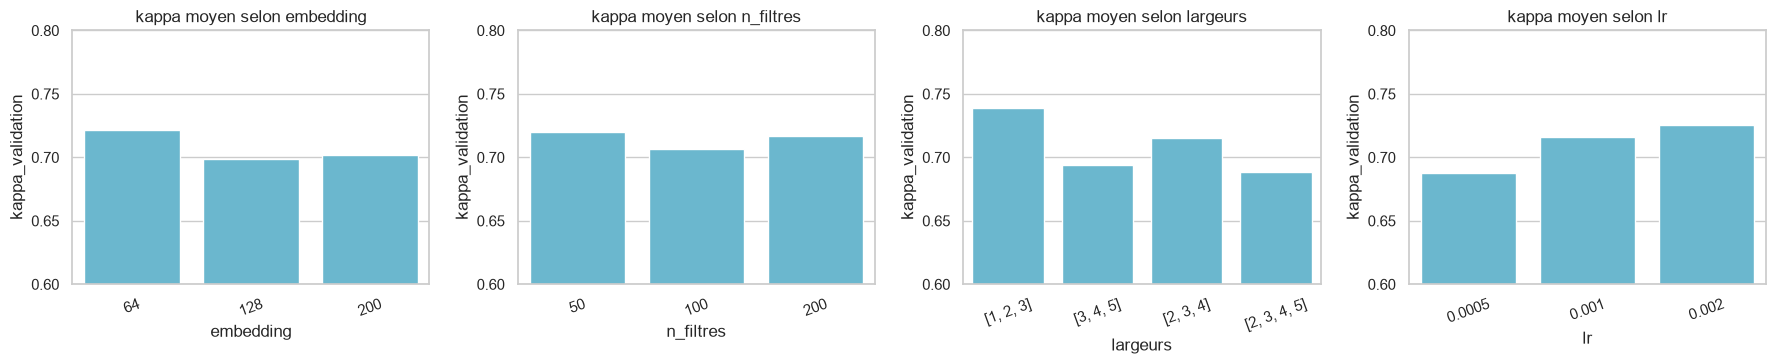

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))

for ax, h in zip(axes, ["embedding", "n_filtres", "largeurs", "lr"]):
    sns.barplot(data=tableau_cnn, x=h, y="kappa_validation", ax=ax, color="#5bc0de", errorbar=None)
    ax.set_ylim(0.6, 0.8)
    ax.set_title(f"kappa moyen selon {h}")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

**Commentaire :** 
Ce qui compte le plus, c'est la largeur des filtres : 1 à 3 mots est nettement devant. Ça confirme que les indices d'aura sont très locaux. Le petit embedding (64) gagne aussi : avec peu de données, un réseau plus gros apprend par cœur. Avec seulement 20 essais, ce sont des tendances, pas des certitudes.

Comme à la fin du TP 2, on regarde les courbes d'apprentissage du meilleur CNN, puis son score sur le test.

Meilleure configuration : {'embedding': 64, 'n_filtres': 100, 'largeurs': [1, 2, 3], 'dropout': 0.5, 'lr': 0.002, 'batch': 64, 'longueur_max': 100, 'epochs_max': 15, 'patience': 3, 'min_freq': 2}


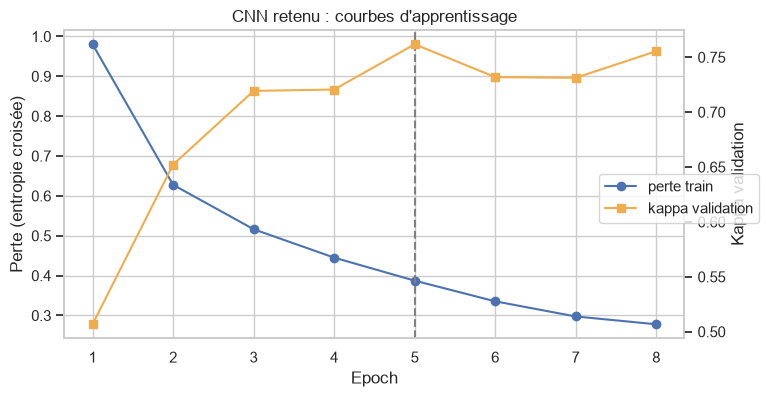

2. CNN → kappa test 0.234 | F1-macro 0.311 | accuracy 36%

               precision    recall  f1-score   support

    Anti-Aura       0.23      0.61      0.33        41
Aura Correcte       0.65      0.38      0.48       191
   Forte Aura       0.17      0.12      0.14        65
  Aura Divine       0.22      0.42      0.29        33

     accuracy                           0.36       330
    macro avg       0.32      0.38      0.31       330
 weighted avg       0.46      0.36      0.38       330



In [24]:
print("Meilleure configuration :", meilleur_cnn["cfg"])

h = meilleur_cnn["hist"]
epochs = range(1, len(h["perte_train"]) + 1)

fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()
ax1.plot(epochs, h["perte_train"], "o-", label="perte train")
ax2.plot(epochs, h["kappa_val"], "s-", color="#f0ad4e", label="kappa validation")
ax1.axvline(meilleur_cnn["meilleure_epoch"], ls="--", color="gray")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Perte (entropie croisée)")
ax2.set_ylabel("Kappa validation")
ax2.grid(False)
fig.legend(loc="center right")
plt.title("CNN retenu : courbes d'apprentissage")
plt.show()

X_test_cnn = encoder(X_test, meilleur_cnn["vocab"], meilleur_cnn["cfg"]["longueur_max"])
y_pred_cnn = predire_proba(meilleur_cnn["modele"], X_test_cnn, DEVICE).argmax(1)
evaluer("2. CNN", y_pred_cnn, meilleur_cnn["temps_s"], meilleur_cnn["n_parametres"])

print()
print(classification_report(y_test, y_pred_cnn, target_names=CLASSES, zero_division=0))

if SAUVEGARDER_MODELES:
    os.makedirs("models/cnn", exist_ok=True)
    torch.save(meilleur_cnn["modele"].state_dict(), "models/cnn/modele.pt")
    json.dump(
        dict(cfg=meilleur_cnn["cfg"], vocab=meilleur_cnn["vocab"],
             val_kappa=meilleur_cnn["kappa_val"], best_epoch=meilleur_cnn["meilleure_epoch"]),
        open("models/cnn/config.json", "w", encoding="utf-8"), ensure_ascii=False
    )
    print("CNN sauvegardé dans models/cnn/")

**Commentaire :** 
La perte du train baisse sans arrêt, mais le kappa de validation plafonne à l'epoch 5 : après, le réseau apprend le train par cœur. L'early stopping arrête tout à l'epoch 8 et garde l'epoch 5.

Sur le test : kappa de 0,23 (36 % d'accuracy). C'est mieux que le SVM, mais lui aussi chute beaucoup. Il retrouve bien les Anti (61 %) et les Divine (42 %), mais presque jamais les Forte (12 %) : il pousse les textes vers les extrêmes.

## Modèle 3 : CamemBERT

**Comment ça marche.** CamemBERT est un Transformer (comme BERT dans le TP 2) qui a déjà lu 138 Go de textes en français. Il connaît la langue, l'ironie, les tournures littéraires. On continue son entraînement sur nos textes pour qu'il apprenne l'aura : c'est le *fine-tuning*.

On a essayé deux façons :
- **classification** : il choisit directement une des 4 classes ;
- **régression** : il prédit le score de −100 à +100, puis on applique les seuils. L'avantage, c'est qu'il sait que les classes ont un ordre.

**Pourquoi CamemBERT ?** Avec quelques milliers de textes, le SVM et le CNN ne peuvent pas apprendre le français. CamemBERT le connaît déjà, il lui reste juste à apprendre l'aura.

**Les hyperparamètres.** Un entraînement prend 7 à 30 minutes sur GPU, donc on a changé un réglage à la fois :

| Hyperparamètre | Valeurs testées |
|---|---|
| Taux d'apprentissage | 2e-5 ; 3e-5 ; 5e-5 |
| Mode | régression ; classification |
| Poids de la classe Divine | ×1 ; ×2 ; ×3 |
| Taille | base (110 M de paramètres) ; large (335 M) |
| Graine aléatoire | 42 ; 43 ; 44 |

Ça fait 11 entraînements, lancés avec `scripts/train_camembert_v2.py` (environ 1 h 45 de GPU). On recharge ici leurs résultats. Pour en relancer un : `ENTRAINER_CAMEMBERT = True`.

In [25]:
DOSSIER_RECHERCHE = "results/recherche_camembert"

if ENTRAINER_CAMEMBERT:
    sortie = f"models/notebook_{CAMEMBERT_MODE}_s{GRAINE}"
    options = ["--class-weights", "--divine-weight", "3"] if CAMEMBERT_MODE == "classification" else []
    subprocess.run([
        sys.executable, "scripts/train_camembert_v2.py",
        "--model", CAMEMBERT_MODELE,
        "--mode", CAMEMBERT_MODE,
        "--lr", str(CAMEMBERT_LR),
        "--seed", str(GRAINE),
        "--out", sortie,
        *options
    ], check=True)
    import shutil
    shutil.copy(f"{sortie}/resultats.json", f"{DOSSIER_RECHERCHE}/{os.path.basename(sortie)}.json")

lignes = []
for fichier in sorted(os.listdir(DOSSIER_RECHERCHE)):
    if fichier.endswith(".json"):
        r = json.load(open(f"{DOSSIER_RECHERCHE}/{fichier}", encoding="utf-8"))
        a = r["args"]
        lignes.append({
            "run": fichier[:-5],
            "taille": "large" if "large" in a["model"] else "base",
            "mode": r["mode"],
            "lr": a["lr"],
            "poids Divine": a["divine_weight"] if a.get("class_weights") else "-",
            "graine": a["seed"],
            "meilleure epoch": r["best_epoch"],
            "minutes": r["temps_entrainement_s"] / 60,
            "kappa_validation": r["val_domaine"]["kappa_quadratique"],
        })

tableau_bert = pd.DataFrame(lignes).set_index("run").sort_values("kappa_validation", ascending=False)
display(tableau_bert.round(3).assign(lr=tableau_bert["lr"].map("{:.0e}".format)))

,taille,mode,lr,poids Divine,graine,meilleure epoch,minutes,kappa_validation
run,,,,,,,,
p2_cls_w3_s42,base,classification,3e-05,3.0,42,5.0,7.859,0.933
p2_cls_w1_s42,base,classification,3e-05,1.0,42,5.0,7.972,0.931
p2_cls_w3_s43,base,classification,3e-05,3.0,43,4.0,7.919,0.929
p2_reg_s42,base,regression,3e-05,-,42,6.0,9.110,0.927
p2_cls_w2_s42,base,classification,3e-05,2.0,42,4.0,7.866,0.925
p2_reg_s43,base,regression,3e-05,-,43,6.0,7.372,0.925
p2_large_reg_s42,large,regression,2e-05,-,42,4.0,29.584,0.921
p2_reg_lr5e-5_s42,base,regression,5e-05,-,42,4.0,7.029,0.921
p2_cls_w3_s44,base,classification,3e-05,3.0,44,3.0,6.601,0.919


**Commentaire :** 
Tous les essais sont entre 0,91 et 0,93 en validation, bien au-dessus du SVM et du CNN (0,75).

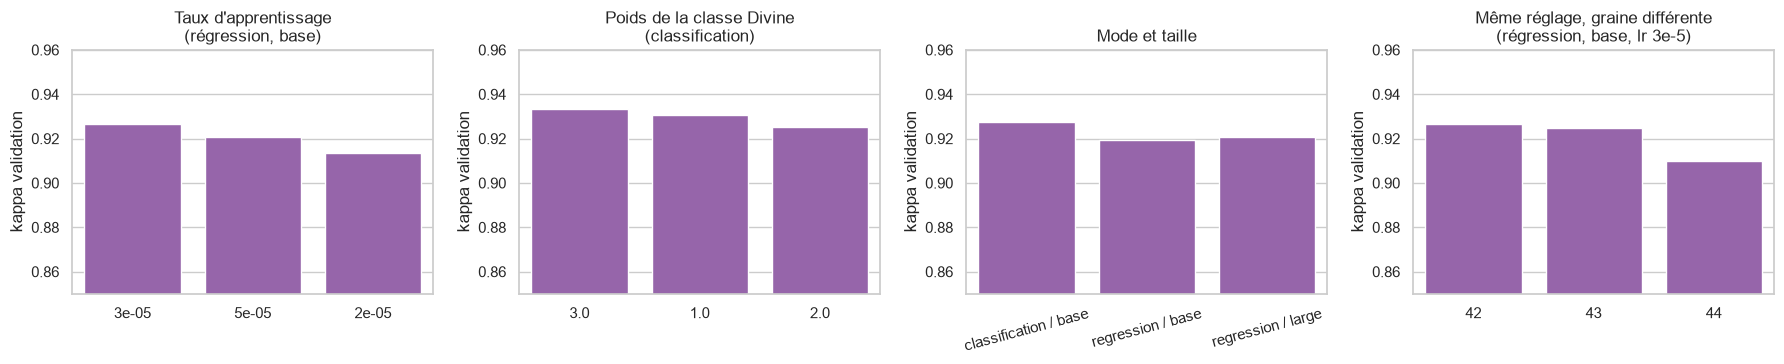

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))

reg_base = tableau_bert[(tableau_bert["mode"] == "regression") & (tableau_bert["taille"] == "base") & (tableau_bert["graine"] == 42)]
sns.barplot(x=reg_base["lr"].map("{:.0e}".format), y=reg_base["kappa_validation"], ax=axes[0], color="#9b59b6")
axes[0].set_title("Taux d'apprentissage\n(régression, base)")

cls = tableau_bert[(tableau_bert["mode"] == "classification") & (tableau_bert["graine"] == 42)]
sns.barplot(x=cls["poids Divine"].astype(str), y=cls["kappa_validation"], ax=axes[1], color="#9b59b6")
axes[1].set_title("Poids de la classe Divine\n(classification)")

mode_taille = tableau_bert.groupby(["mode", "taille"])["kappa_validation"].mean().reset_index()
sns.barplot(x=mode_taille["mode"] + " / " + mode_taille["taille"], y=mode_taille["kappa_validation"], ax=axes[2], color="#9b59b6")
axes[2].set_title("Mode et taille")
axes[2].tick_params(axis="x", rotation=15)

graines = tableau_bert[(tableau_bert["mode"] == "regression") & (tableau_bert["taille"] == "base") & (tableau_bert["lr"] == 3e-5)]
sns.barplot(x=graines["graine"].astype(str), y=graines["kappa_validation"], ax=axes[3], color="#9b59b6")
axes[3].set_title("Même réglage, graine différente\n(régression, base, lr 3e-5)")

for ax in axes:
    ax.set_ylim(0.85, 0.96)
    ax.set_ylabel("kappa validation")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

**Commentaire :** 
3e-5 est le meilleur taux d'apprentissage, et le poids ×3 sur Divine aide un tout petit peu. Le modèle *large* n'est pas meilleur seul, alors qu'il est 4 fois plus lent.

Le plus intéressant est le dernier graphique : avec les mêmes réglages et une graine différente, le kappa varie de 0,910 à 0,927. Le hasard pèse autant que les réglages. Comme aucun réglage ne se détache, on a eu l'idée de combiner plusieurs modèles.

### Le modèle retenu : un ensemble de 4 CamemBERT

On fait la moyenne pondérée de 4 modèles :

$$
\text{score} = 0{,}6 \times \text{score}_{\text{large, régression}} + 0{,}4 \times \text{moyenne des 3 base en classification}
$$

Pour les modèles en classification, on transforme les probabilités en score avec le score moyen de chaque classe (−55, 7, 50 et 87). Ensuite, on applique des seuils réajustés sur la validation (−12 / 36 / 69).

L'idée : des modèles qui ne se trompent pas de la même façon se corrigent entre eux.

Les poids des 4 modèles (2,6 Go) sont trop lourds pour GitHub, on les a mis sur Hugging Face. La cellule suivante les télécharge, puis fait passer les 330 textes du test dedans. Pas d'entraînement ici, juste des prédictions.

In [27]:
choix = json.load(open("results/p2_choix.json", encoding="utf-8"))
retenu = choix["candidats"][choix["meilleur"]]

print("Composants de l'ensemble (α_m) :")
for nom, poids in retenu["composants"].items():
    print(f"   {nom:<20} {poids:.2f}")
print("Seuils réajustés :", retenu["seuils"])
print("Kappa de validation de l'ensemble :", round(retenu["val_kappa"], 3))
print()

CENTRES = np.array([-55, 7, 50, 87])   # score moyen de chaque classe, c_k


def score_camembert(dossier, textes, lot=32):
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok = AutoTokenizer.from_pretrained(dossier)
    m = AutoModelForSequenceClassification.from_pretrained(dossier).to(DEVICE).eval()
    scores = []
    with torch.no_grad():
        for i in range(0, len(textes), lot):
            enc = tok(list(textes[i:i + lot]), padding=True, truncation=True, max_length=256, return_tensors="pt").to(DEVICE)
            o = m(**enc).logits.float().cpu()
            # régression : score = sortie × 100 ; classification : score = Σ p_k × c_k
            scores.append(o.reshape(-1).numpy() * 100 if o.shape[1] == 1 else o.softmax(1).numpy() @ CENTRES)
    return np.concatenate(scores)


def score_ensemble(textes):
    # s(x) = Σ α_m s_m(x)
    return sum(poids * score_camembert(f"models/{nom}/final", textes) for nom, poids in composants.items())


# Les poids des 4 CamemBERT (≈ 2,6 Go) sont sur Hugging Face : on les télécharge s'ils manquent
composants = {n: w for n, w in retenu["composants"].items() if n != "tfidf" and w > 0}
camembert_dispo = False
try:
    import hf_modeles
    camembert_dispo = hf_modeles.telecharger()
except Exception as e:
    print("Téléchargement depuis Hugging Face impossible :", e)

if camembert_dispo:
    # Pas d'entraînement ici : on fait seulement passer les 330 textes du test dans les modèles
    import transformers
    transformers.logging.set_verbosity_error()
    start = time.perf_counter()
    s_test = score_ensemble(X_test.tolist())
    y_pred_bert = np.digitize(s_test, retenu["seuils"])
    print(f"Prédictions calculées en direct sur {DEVICE} en {time.perf_counter() - start:.0f} secondes")
else:
    # Sinon, on relit les prédictions calculées sur GPU par notre script
    y_pred_bert = pd.read_csv("results/predictions_phase2.csv", encoding="utf-8-sig")["prediction"].map(CLASSES.index).values
    print("Prédictions relues dans results/predictions_phase2.csv")

infos = [json.load(open(f"{DOSSIER_RECHERCHE}/{n}.json")) for n in retenu["composants"] if n != "tfidf"]
evaluer("3. CamemBERT (ensemble)", y_pred_bert,
        sum(i["temps_entrainement_s"] for i in infos), sum(i["n_parametres"] for i in infos))

print()
print(classification_report(y_test, y_pred_bert, target_names=CLASSES, zero_division=0))

Composants de l'ensemble (α_m) :
   p2_large_reg_s42     0.60
   p2_cls_w3_s42        0.13
   p2_cls_w3_s43        0.13
   p2_cls_w3_s44        0.13
Seuils réajustés : [-12, 36, 69.0]
Kappa de validation de l'ensemble : 0.949



Prédictions calculées en direct sur mps en 12 secondes
3. CamemBERT (ensemble) → kappa test 0.389 | F1-macro 0.455 | accuracy 59%

               precision    recall  f1-score   support

    Anti-Aura       0.38      0.51      0.43        41
Aura Correcte       0.73      0.77      0.75       191
   Forte Aura       0.35      0.32      0.34        65
  Aura Divine       0.50      0.21      0.30        33

     accuracy                           0.59       330
    macro avg       0.49      0.45      0.45       330
 weighted avg       0.59      0.59      0.58       330



**Commentaire :** 
L'ensemble atteint 0,949 en validation, mieux que n'importe quel modèle seul. Sur le test : kappa de 0,39 et 59 % d'accuracy. Lui aussi chute, mais beaucoup moins que les deux autres : face à des textes d'un style nouveau, il s'appuie sur sa connaissance du français.

On obtient exactement le même kappa que notre script d'entraînement, donc les modèles sur Hugging Face sont bien les bons.

## Comparaison des trois modèles sur le test

C'est la seule fois où on utilise le test.

In [28]:
tableau = pd.DataFrame(RESULTATS).T

display(tableau.style.format(
    {c: "{:.3f}" for c in ["kappa", "F1-macro"]}
    | {c: "{:.0%}" for c in tableau.columns if "rappel" in c or c in ("accuracy", "à ±1 classe")}
    | {"entraînement (s)": lambda v: "" if pd.isna(v) else f"{v:.0f}",
       "paramètres": lambda v: "" if pd.isna(v) else f"{int(v):,}".replace(",", " ")}
))

,kappa,F1-macro,accuracy,à ±1 classe,rappel Anti,rappel Corr,rappel Fort,rappel Divi,entraînement (s),paramètres
Toujours « Aura Correcte »,0.000,0.183,58%,90%,0%,100%,0%,0%,,
Hasard,-0.075,0.202,23%,65%,20%,23%,29%,18%,,
1. SVM,0.147,0.297,35%,82%,46%,37%,32%,18%,1,242 380
2. CNN,0.234,0.311,36%,80%,61%,38%,12%,42%,12,312 736
3. CamemBERT (ensemble),0.389,0.455,59%,92%,51%,77%,32%,21%,3118,668 537 613


**Commentaire :** 
CamemBERT est devant sur toutes les métriques. C'est le seul qui fait mieux que « toujours Correcte » en accuracy. En échange, il est beaucoup plus lourd : 668 millions de paramètres et 50 minutes de GPU, contre 1 seconde pour le SVM.

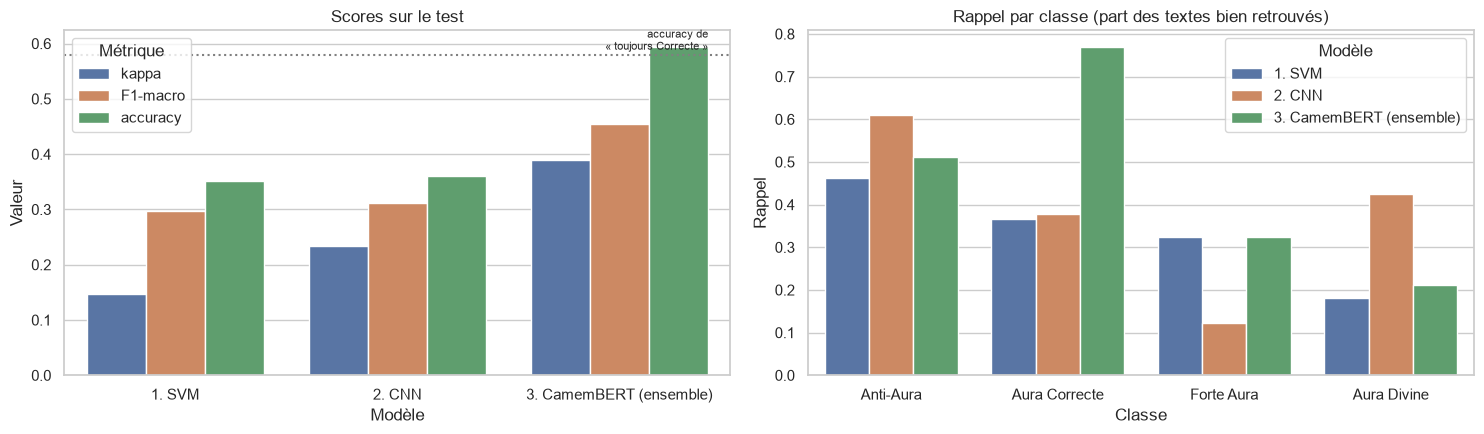

In [29]:
modeles = [n for n in RESULTATS if n[0].isdigit()]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

scores = pd.DataFrame([
    {"Modèle": n, "Métrique": m, "Valeur": RESULTATS[n][m]}
    for n in modeles for m in ["kappa", "F1-macro", "accuracy"]
])
sns.barplot(data=scores, x="Modèle", y="Valeur", hue="Métrique", ax=axes[0])
axes[0].axhline(RESULTATS["Toujours « Aura Correcte »"]["accuracy"], ls=":", color="gray")
axes[0].text(2.4, RESULTATS["Toujours « Aura Correcte »"]["accuracy"] + 0.01, "accuracy de\n« toujours Correcte »", ha="right", fontsize=8)
axes[0].set_title("Scores sur le test")

rappels = pd.DataFrame([
    {"Modèle": n, "Classe": c, "Rappel": RESULTATS[n][f"rappel {cc}"]}
    for n in modeles for c, cc in zip(CLASSES, COURT)
])
sns.barplot(data=rappels, x="Classe", y="Rappel", hue="Modèle", ax=axes[1])
axes[1].set_title("Rappel par classe (part des textes bien retrouvés)")

plt.tight_layout()
plt.show()

**Commentaire :** 
La grosse différence vient de la classe « Correcte » : le SVM et le CNN n'en retrouvent que 37-38 %, CamemBERT 77 %. Comme c'est 58 % du test, ça pèse lourd. Par contre, le CNN est le meilleur sur les classes rares (Anti et Divine). Forte reste difficile pour tout le monde.

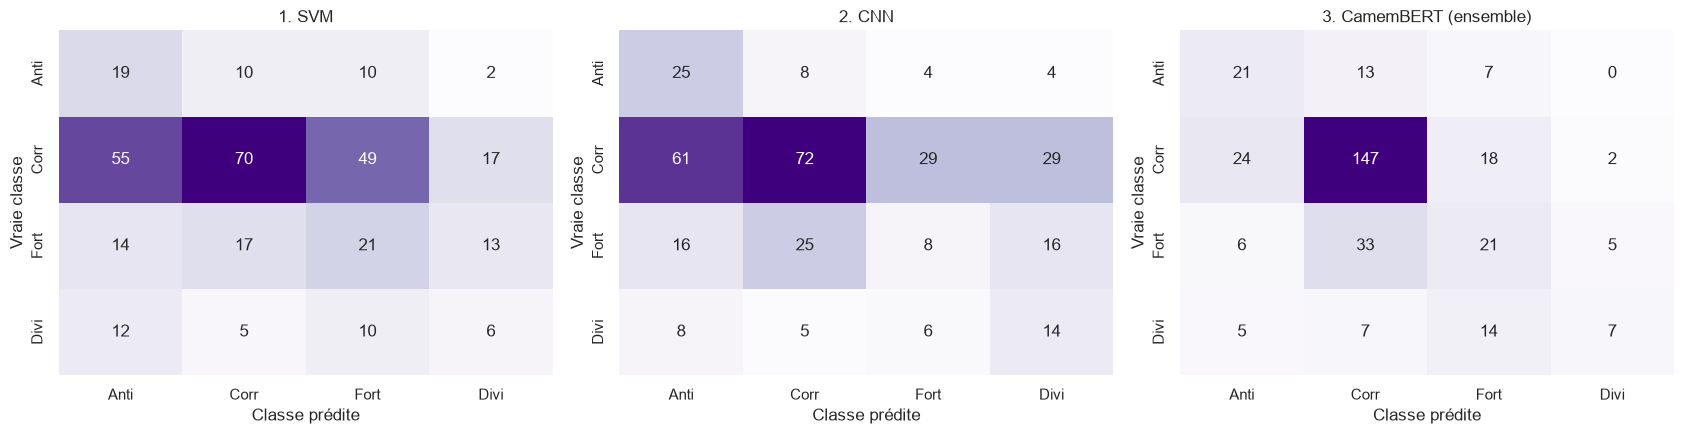

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, n in zip(axes, modeles):
    m = confusion_matrix(y_test, PREDICTIONS[n], labels=range(4))
    sns.heatmap(m, annot=True, fmt="d", cmap="Purples", cbar=False,
                xticklabels=COURT, yticklabels=COURT, ax=ax)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Vraie classe")
    ax.set_title(n)

plt.tight_layout()
plt.show()

**Commentaire :** 
Pour le SVM et le CNN, la ligne « Corr » est très étalée : sur 191 textes Correcte, le SVM en met 55 en Anti et 49 en Forte. Ils voient de l'aura dans des phrases banales.

CamemBERT a une diagonale bien plus marquée, et ses erreurs sont surtout d'une seule classe (Forte confondu avec Correcte). Les grosses erreurs Anti ↔ Divine sont rares.

In [31]:
# Accuracy par type de texte : où chaque modèle est-il bon ?
types = test["type"].values
principaux = pd.Series(types).value_counts().index[:9]

par_type = pd.DataFrame({
    n: {t: np.mean(PREDICTIONS[n][types == t] == y_test[types == t]) for t in principaux}
    for n in modeles
})
par_type.insert(0, "nombre de textes", pd.Series(types).value_counts()[:9])

display(par_type.style.format({n: "{:.0%}" for n in modeles}))

,nombre de textes,1. SVM,2. CNN,3. CamemBERT (ensemble)
discours,101,37%,30%,58%
interjection,65,37%,37%,86%
théâtre,35,17%,34%,31%
poésie,22,23%,45%,23%
question,20,35%,45%,85%
réponse,18,22%,22%,67%
roman,11,64%,45%,36%
prose,10,30%,40%,50%
texte officiel,9,44%,56%,67%


**Commentaire :** 
CamemBERT est très bon sur les interjections et les questions de l'Assemblée (plus de 85 %), mais faible sur le théâtre et la poésie, où le CNN fait même mieux. Ce sont les textes les plus éloignés de notre train. Les petits groupes (une dizaine de textes) sont trop petits pour conclure.

### Bilan

| | Kappa validation | Kappa test | Accuracy test | Entraînement |
|---|---|---|---|---|
| SVM | 0,74 | 0,15 | 35 % | 1 seconde |
| CNN | 0,76 | 0,23 | 36 % | 12 secondes |
| CamemBERT | 0,95 | **0,39** | **59 %** | 50 minutes de GPU |

- CamemBERT gagne nettement : le pré-entraînement fait toute la différence.
- Tous les modèles chutent entre la validation et le test : notre validation était trop facile.
- Il y a un plafond : quand deux IA annotent les mêmes textes, elles ne sont d'accord qu'à 0,61 de kappa. L'aura est subjective, même un modèle parfait ne ferait pas beaucoup mieux.

## Test sur des phrases choisies

Comme à la fin du TP Banking77, on teste nos trois modèles sur quelques phrases. On peut changer `PHRASES_DEMO` dans les paramètres.

In [32]:
demo = pd.DataFrame({"phrase": PHRASES_DEMO})
demo["SVM"] = [CLASSES[k] for k in svm.predict(PHRASES_DEMO)]
demo["CNN"] = [CLASSES[k] for k in predire_proba(
    meilleur_cnn["modele"], encoder(PHRASES_DEMO, meilleur_cnn["vocab"], 100), DEVICE).argmax(1)]

if camembert_dispo:
    s_demo = score_ensemble(PHRASES_DEMO)
    demo["CamemBERT (score)"] = [f"{CLASSES[k]} ({s:+.0f})" for k, s in zip(np.digitize(s_demo, retenu["seuils"]), s_demo)]
else:
    print("Poids de CamemBERT indisponibles : démo faite avec le SVM et le CNN seulement.")

pd.set_option("display.max_colwidth", 80)
display(demo)

,phrase,SVM,CNN,CamemBERT (score)
0,Je me suis chié dessus,Anti-Aura,Anti-Aura,Anti-Aura (-42)
1,"La bière c'est comme ma femme, brune et amer",Anti-Aura,Anti-Aura,Anti-Aura (-44)
2,fort en chocolat,Aura Correcte,Aura Correcte,Anti-Aura (-22)
3,"dab dab, six-seven",Aura Correcte,Aura Correcte,Anti-Aura (-43)
4,"un accident de train a eu lieu en espagne ce samedi,",Aura Correcte,Aura Correcte,Aura Correcte (-4)
5,"En imposer pour ne pas avoir à imposer, voilà en quoi consiste le charisme.",Aura Divine,Forte Aura,Forte Aura (+68)
6,"Loin des yeux, loin du cœur",Aura Correcte,Anti-Aura,Aura Correcte (-6)


**Commentaire :** 
Les phrases vulgaires sont classées Anti-Aura par les trois modèles : là, le vocabulaire suffit. Mais pour « dab dab, six-seven », le SVM et le CNN disent « Correcte » : ils ne connaissent pas ces mots. CamemBERT le met bien en Anti-Aura. La maxime sur le charisme est vue comme Forte par le CNN et CamemBERT.

## Ce qui se passe quand on envoie un texte dans la WebApp

Jusqu'ici on travaillait sur des CSV propres. Dans la WebApp, l'utilisateur colle un texte ou dépose n'importe quel fichier. On suit ici ce qui arrive à ce texte, en appelant les vraies fonctions de notre back-end (`backend/extract.py` et `backend/model.py`).

1. **Le front** (`frontend/app.js`) envoie le texte ou le fichier, et le modèle choisi, à l'API (`POST /api/predict`).
2. **L'API** vérifie la taille (10 Mo max) et extrait le texte du fichier.
3. Si le texte fait moins de 3 caractères, elle renvoie une erreur.
4. Sinon, le texte passe dans le modèle choisi (CamemBERT par défaut).
5. L'API renvoie la classe, la probabilité et le score, et le front les affiche.

### Du fichier au texte

La méthode dépend de l'extension du fichier :

| Format | Ce qu'on fait |
|---|---|
| PDF | `pypdf` lit le texte de chaque page |
| Word (.docx) | `python-docx` lit chaque paragraphe |
| PowerPoint (.pptx) | `python-pptx` lit le texte de chaque diapo |
| HTML | on enlève les balises, le CSS et le JavaScript |
| JSON | on garde seulement les textes |
| le reste (.txt, .md…) | on lit le fichier tel quel |

Puis on remplace tous les retours à la ligne et espaces en trop par un seul espace.

In [33]:
import io
import sys
sys.path.insert(0, "..")   # dossier racine du projet, pour importer le back-end de la WebApp

from backend.extract import extract_text

# On fabrique quelques « fichiers » comme ceux qu'un utilisateur pourrait déposer
from docx import Document
doc = Document()
doc.add_paragraph("Vous avez la mémoire courte")
doc.add_paragraph("et le discours long !")
fichier_docx = io.BytesIO()
doc.save(fichier_docx)

fichiers = {
    "message.txt": "Le chaos,\n\n   c'est vous !".encode("utf-8"),
    "ancien_fichier.txt": "Le chaos, c'est vous !".encode("latin-1"),   # encodage Windows d'avant
    "page.html": b"<html><style>p{color:red}</style><body><h1>Titre</h1><p>Loin des yeux, <b>loin du coeur</b></p></body></html>",
    "donnees.json": '{"auteur": "Cyrano", "replique": "C\'est bien plus beau lorsque c\'est inutile !", "annee": 1897}'.encode("utf-8"),
    "replique.docx": fichier_docx.getvalue(),
    "projet_final.pdf": open("../docs/projet_final.pdf", "rb").read(),
}

for nom, octets in fichiers.items():
    texte = extract_text(nom, octets)
    print(f"{nom:<20} ({len(octets):>6} octets) → {len(texte):>4} caractères : {texte[:90]!r}")

message.txt          (    26 octets) →   22 caractères : "Le chaos, c'est vous !"
ancien_fichier.txt   (    22 octets) →   22 caractères : "Le chaos, c'est vous !"
page.html            (   109 octets) →   34 caractères : 'Titre Loin des yeux, loin du coeur'
donnees.json         (    95 octets) →   51 caractères : "Cyrano C'est bien plus beau lorsque c'est inutile !"
replique.docx        ( 36621 octets) →   49 caractères : 'Vous avez la mémoire courte et le discours long !'
projet_final.pdf     (105130 octets) → 1139 caractères : 'Projet final de classification de textes - Mastère Dev, Data & IA Ekaterina TOMILINA 19 no'


**Commentaire :** 
Tous les formats donnent une chaîne de texte propre. Le vieux fichier Windows est bien lu (on essaie plusieurs encodages), le CSS du HTML disparaît, et l'année du JSON est ignorée.

Deux limites : un document entier comme le PDF du sujet (1 139 caractères) ne ressemble pas à nos textes d'entraînement, d'une phrase, donc le résultat est à prendre avec des pincettes. Et un PDF scanné ne contient pas de texte, seulement des images des pages : `pypdf` ne trouve rien et l'API répond « Aucun texte détecté ».

Pour ça, il faudrait de l'**OCR** (reconnaissance optique de caractères) : un logiciel qui « lit » les lettres dans une image et les transforme en texte, comme quand on scanne un document avec son téléphone. On ne l'a pas fait parce que l'outil le plus courant, Tesseract, est un programme à installer en plus sur le serveur, ce qui alourdit le déploiement. Et dans notre cas, les PDF qu'on utilise contiennent déjà du texte. Pour l'ajouter, il suffirait de lancer Tesseract (avec la librairie `pytesseract`) quand `pypdf` renvoie un texte vide, et aussi sur les images (.png, .jpg).

### Ce que chaque modèle fait du texte

L'API appelle `registry.predict(modele, texte)`. Le registre charge chaque modèle une seule fois, puis le garde en mémoire. On prend une phrase et on regarde ce que voit chaque modèle.

In [34]:
import numpy as np
from backend.model import Registry

registry = Registry()
print("Modèles disponibles dans la WebApp :")
for m in registry.liste():
    print(f"   {m['id']:<10} {m['label']:<30} {'(par défaut)' if m['default'] else ''}")

TEXTE = extract_text("message.txt", fichiers["message.txt"])
print("\nTexte reçu par les modèles :", repr(TEXTE))

Modèles disponibles dans la WebApp :
   camembert  ⭐ CamemBERT (modèle retenu)    (par défaut)
   svm        SVM                            
   cnn        CNN                            

Texte reçu par les modèles : "Le chaos, c'est vous !"


**Commentaire :** 
Les trois modèles sont disponibles. Si CamemBERT ne peut pas être téléchargé (pas d'internet par exemple), la WebApp continue de marcher avec le SVM et le CNN.

**Le SVM.** Le texte passe dans le même TF-IDF qu'à l'entraînement, avec le vocabulaire du train. Un mot jamais vu est simplement ignoré.

In [35]:
_, svm_webapp = registry.get("svm")
tfidf = svm_webapp.pipe["tfidf"]

vecteur = tfidf.transform([TEXTE])
noms = tfidf.get_feature_names_out()
print(f"Taille du vecteur : {vecteur.shape[1]} colonnes, dont {vecteur.nnz} non nulles")

# les termes du texte qui ont le plus de poids TF-IDF
idx = vecteur.toarray()[0].argsort()[::-1][:8]
print("Termes les plus importants :", [(noms[i].replace("__", " : "), round(float(vecteur[0, i]), 3)) for i in idx])

classe, proba, score = svm_webapp.predire(TEXTE)
print("\nProbabilités :", {c: round(float(p), 3) for c, p in zip(CLASSES, proba)})
print("Classe prédite :", CLASSES[classe], "| score =", round(score, 1))

Taille du vecteur : 60594 colonnes, dont 47 non nulles
Termes les plus importants : [('mots : est vous', 0.581), ('mots : le chaos', 0.531), ('mots : chaos', 0.531), ('caracteres : os,', 0.287), ('caracteres : os, ', 0.287), ('caracteres : hao', 0.257), ('caracteres : chao', 0.257), ('caracteres : chaos', 0.257)]

Probabilités : {'Anti-Aura': 0.653, 'Aura Correcte': 0.074, 'Forte Aura': 0.213, 'Aura Divine': 0.06}
Classe prédite : Anti-Aura | score = -19.6


**Commentaire :** 
La phrase devient un vecteur de 60 594 colonnes, dont seulement 47 non nulles. Les termes les plus forts sont « c'est vous » et « le chaos ».

Le SVM ne donne pas de score d'aura, alors le back-end en calcule un : c'est la moyenne des scores de chaque classe (−55, 7, 50, 87), pondérée par les probabilités. Ici −20 : le modèle penche pour Anti, mais garde 21 % sur Forte, ce qui remonte le score.

**Le CNN.** Le texte est découpé en mots, puis chaque mot est remplacé par son numéro dans le vocabulaire du train.

In [36]:
import cnn   # ml/scripts/cnn.py, utilisé par la WebApp

_, cnn_webapp = registry.get("cnn")
config = json.load(open("models/cnn/config.json", encoding="utf-8"))
vocab_cnn = config["vocab"]

tokens = cnn.tokeniser(TEXTE)
ids = cnn.encoder([TEXTE], vocab_cnn, config["cfg"]["longueur_max"])
print("Tokens :", tokens)
print("Numéros :", ids[0].tolist(), " (1 = mot inconnu, 0 = remplissage)")
print("Mots inconnus du vocabulaire :", [t for t in tokens if t not in vocab_cnn])

classe, proba, score = cnn_webapp.predire(TEXTE)
print("\nProbabilités :", {c: round(float(p), 3) for c, p in zip(CLASSES, proba)})
print("Classe prédite :", CLASSES[classe], "| score =", round(score, 1))

Tokens : ['le', 'chaos', ',', "c'", 'est', 'vous', '!']
Numéros : [2099, 756, 9, 656, 1481, 4065, 2]  (1 = mot inconnu, 0 = remplissage)
Mots inconnus du vocabulaire : []

Probabilités : {'Anti-Aura': 0.982, 'Aura Correcte': 0.012, 'Forte Aura': 0.005, 'Aura Divine': 0.001}
Classe prédite : Anti-Aura | score = -53.6


**Commentaire :** 
Les 7 mots sont connus. Un mot absent du vocabulaire deviendrait 1 (« inconnu ») et le réseau ne saurait rien de lui : c'est la grande faiblesse d'un modèle appris de zéro. Ici, le CNN est sûr de lui à 98 % : il pousse vers les extrêmes, comme sur le test.

**CamemBERT.** Il découpe le texte en sous-mots : un mot rare est coupé en morceaux qu'il connaît, donc aucun mot n'est jamais inconnu. Le texte passe ensuite dans les 4 modèles de l'ensemble, et on fait la moyenne pondérée vue plus haut.

Pour afficher une probabilité dans la WebApp, le back-end la calcule à partir de la distance entre le score et le centre de chaque classe : plus le score est proche du centre d'une classe, plus sa probabilité est grande.

In [37]:
import transformers
from transformers import AutoTokenizer
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()

_, camembert_webapp = registry.get("camembert")

tok = AutoTokenizer.from_pretrained("models/p2_large_reg_s42/final")
print("Sous-mots :", tok.tokenize(TEXTE))
print("Mot inventé :", tok.tokenize("skibidi rizzler"))

# score de chacun des 4 modèles de l'ensemble, puis moyenne pondérée
import torch
choix_webapp = json.load(open("results/p2_choix.json", encoding="utf-8"))
noms_composants = [n for n, w in choix_webapp["candidats"][choix_webapp["meilleur"]]["composants"].items() if n != "tfidf" and w > 0]

total = 0
with torch.no_grad():
    for nom, (poids, tokenizer, modele) in zip(noms_composants, camembert_webapp.parts):
        sortie = modele(**tokenizer([TEXTE], truncation=True, max_length=256, return_tensors="pt")).logits[0].numpy()
        if sortie.size == 1:
            s_m = float(sortie[0]) * 100                                          # régression
        else:
            p = np.exp(sortie - sortie.max()); s_m = float((p / p.sum()) @ np.array([-55, 7, 50, 87]))  # classification
        total += poids * s_m
        print(f"   {nom:<18} poids {poids:.2f}  →  score {s_m:+.1f}")
print(f"Score de l'ensemble : {total:+.1f}")

classe, proba, score = camembert_webapp.predire(TEXTE)
print("\nProbabilités affichées :", {c: round(float(p), 3) for c, p in zip(CLASSES, proba)})
print("Classe prédite :", CLASSES[classe], "| score =", round(score, 1))

Sous-mots : ['▁Le', '▁chaos', ',', '▁c', "'", 'est', '▁vous', '▁!']
Mot inventé : ['▁ski', 'bi', 'di', '▁riz', 'z', 'ler']
   p2_large_reg_s42   poids 0.60  →  score -0.3


   p2_cls_w3_s42      poids 0.13  →  score -54.5
   p2_cls_w3_s43      poids 0.13  →  score -54.7


   p2_cls_w3_s44      poids 0.13  →  score -53.9
Score de l'ensemble : -22.0

Probabilités affichées : {'Anti-Aura': 0.419, 'Aura Correcte': 0.526, 'Forte Aura': 0.048, 'Aura Divine': 0.006}
Classe prédite : Anti-Aura | score = -22.0


**Commentaire :** 
« skibidi rizzler » est découpé en morceaux connus (« ski », « bi », « di »…), alors que le CNN n'y verrait que deux mots inconnus.

Les 4 modèles ne sont pas d'accord : le large trouve la phrase neutre (−0,3), les trois autres nettement Anti (−54). La moyenne donne −22, donc Anti-Aura.

**Un problème qu'on a trouvé avec ce test.** La classe vient des seuils (−22 < −12, donc Anti), mais la probabilité vient de la distance aux centres, et −22 est un peu plus près du centre de Correcte (7) que de celui d'Anti (−55). Résultat : la WebApp affiche « Anti-Aura, 42 % », mais la barre « Correcte » est plus haute (53 %). Pour CamemBERT, la probabilité affichée est donc plutôt un indicateur de confiance. Il faudrait la calculer à partir des seuils.

### La réponse envoyée au front

On appelle exactement la même fonction que l'API :

In [38]:
reponse = registry.predict("", TEXTE)   # "" = modèle par défaut, comme si l'utilisateur ne choisissait rien
reponse.update(filename="message.txt", n_chars=len(TEXTE), preview=TEXTE[:280])   # ajouté par l'API

print(json.dumps(reponse, indent=2, ensure_ascii=False))

{
  "category": "Anti-Aura",
  "probability": 0.41916933150783386,
  "score": -22,
  "probabilities": [
    {
      "label": "Aura Correcte",
      "probability": 0.5263649597105087
    },
    {
      "label": "Anti-Aura",
      "probability": 0.41916933150783386
    },
    {
      "label": "Forte Aura",
      "probability": 0.04828427426202223
    },
    {
      "label": "Aura Divine",
      "probability": 0.006181434519635232
    }
  ],
  "model": {
    "id": "camembert",
    "label": "⭐ CamemBERT (modèle retenu)"
  },
  "demo": false,
  "filename": "message.txt",
  "n_chars": 22,
  "preview": "Le chaos, c'est vous !"
}


**Commentaire :** 
Avec ce JSON, le front affiche :
- la classe, avec sa couleur, son emoji et une petite phrase ;
- la probabilité, avec un message selon la confiance (« Le modèle hésite » sous 60 %) ;
- les points d'aura : le score × 100, ici −2 200 ;
- un GIF au hasard dans le dossier `Assets/` de la classe ;
- les barres des 4 probabilités, et un aperçu du texte pour vérifier que l'extraction a marché.

`category` et `probability`, c'est ce que demandait le sujet : la catégorie et la probabilité associée. On voit aussi le problème d'au-dessus : la première barre est « Correcte » alors que la classe est « Anti-Aura ».

### Les trois modèles sur un fichier Word

On dépose le même `.docx` et on essaie les trois modèles :

In [39]:
texte_docx = extract_text("replique.docx", fichiers["replique.docx"])
print("Texte extrait du .docx :", repr(texte_docx), "\n")

lignes = []
for id_modele in ["svm", "cnn", "camembert"]:
    r = registry.predict(id_modele, texte_docx)
    lignes.append({
        "modèle": r["model"]["label"],
        "classe": r["category"],
        "probabilité": f"{r['probability']:.0%}",
        "score": r["score"],
        "points d'aura": r["score"] * 100,
    })
display(pd.DataFrame(lignes))

Texte extrait du .docx : 'Vous avez la mémoire courte et le discours long !' 



,modèle,classe,probabilité,score,points d'aura
0,SVM,Aura Correcte,54%,25,2500
1,CNN,Aura Correcte,84%,4,400
2,⭐ CamemBERT (modèle retenu),Aura Correcte,88%,6,600


**Commentaire :** 
Le texte du Word est bien reconstitué. Les trois modèles disent « Correcte », alors qu'on avait donné cette phrase en intro comme exemple de Forte Aura. Le SVM est juste à la limite (score 25). Les piques politiques courtes restent difficiles pour nos modèles.

## Conclusion

On retient **CamemBERT**, et c'est lui qu'utilise la WebApp par défaut. Il a les meilleurs scores et c'est le seul des trois qui comprend vraiment la langue. Son défaut : il est lourd et il faut un GPU pour l'entraîner. Le SVM et le CNN restent dans la WebApp pour comparer.

Ce qu'on retient du projet :
1. **Le choix du modèle compte plus que les réglages.** Les hyperparamètres nous ont fait gagner quelques centièmes. Passer à un modèle pré-entraîné a fait passer le kappa de 0,15-0,23 à 0,39.
2. **Les données comptent autant que le modèle.** Nos plus gros progrès sont venus des textes écrits dans le style des vrais textes.
3. **La validation doit ressembler au vrai usage.** La nôtre était trop facile et surestimait les résultats.

Pour aller plus loin : faire annoter nos textes par des humains, construire une validation avec de vrais textes, et ajouter du théâtre et de la poésie, où nos modèles sont les plus faibles.